In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fluids.navier import NavierStokesSolver, solve_NS

In [3]:
# physical parameters
rho = 1000 # kgm^-3
nu = 0.001/rho # Pa s / kgm^-3


Nx, Ny = 101, 101
dx, dy = 0.1, 0.1

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

p = np.zeros_like(X)

p_exact = np.cos(np.pi * X / Lx) * np.cos(np.pi * Y / Ly)

f = -((np.pi / Lx) ** 2 + (np.pi / Ly) ** 2) * p_exact

solver = NavierStokesSolver(Pmax=1, p=p, u=None, v=None, nu=nu, rho=rho, Lx=Lx, Ly=Ly, Nx=Nx, Ny=Ny)

In [5]:
p_solve = solver.pressure_poisson_jacobi(RHS=f)

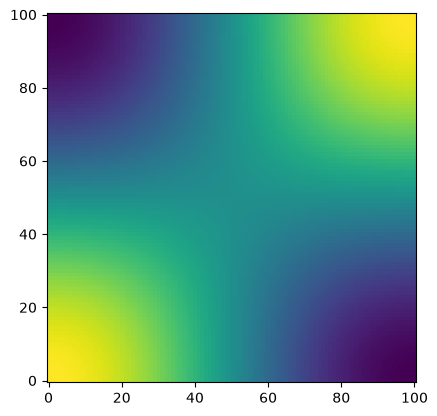

In [6]:
plt.imshow(p_solve, cmap="viridis", origin="lower")

In [22]:
Nx, Ny = 101, 101
dx, dy = 0.1, 0.1

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

p = np.zeros_like(X)

p_exact = np.cos(np.pi * X / Lx) * np.cos(np.pi * Y / Ly)

f = -((np.pi / Lx) ** 2 + (np.pi / Ly) ** 2) * p_exact

In [23]:
new_p = pressure_poisson_jacobi(p, dx, dy, f, logs=True)

PPE solve iterations = 7822


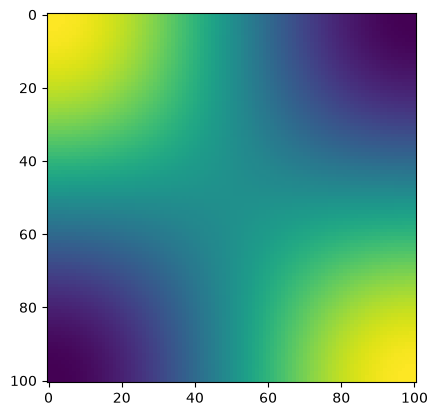

In [24]:
plt.imshow(new_p)

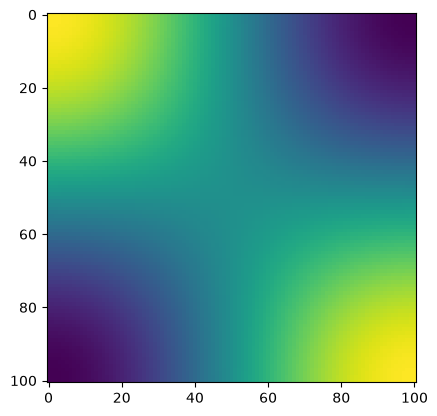

In [25]:
plt.imshow(p_exact)


Time = 0.00100000
PPE solve iterations = 10174
velocity residual = 1.3217132101537539

Time = 0.00200000
PPE solve iterations = 16250
velocity residual = 0.4289522906458565

Time = 0.00300000
PPE solve iterations = 9791
velocity residual = 0.24093922368073808

Time = 0.00400000
PPE solve iterations = 1785
velocity residual = 0.1615953662770112

Time = 0.00500000
PPE solve iterations = 1986
norm(u) = 0.64563121, norm(v) = 0.30950948
Courant number: 0.00598543
velocity residual = 0.11826238701260497

Time = 0.00600000
PPE solve iterations = 3104
velocity residual = 0.09118372700845649

Time = 0.00700000
PPE solve iterations = 2569
velocity residual = 0.07284901360244088

Time = 0.00800000
PPE solve iterations = 2263
velocity residual = 0.05978175527574793

Time = 0.00900000
PPE solve iterations = 2323
velocity residual = 0.050144834190262264

Time = 0.01000000
PPE solve iterations = 2474
norm(u) = 0.57577988, norm(v) = 0.33246839
Courant number: 0.00518059
velocity residual = 0.04286944

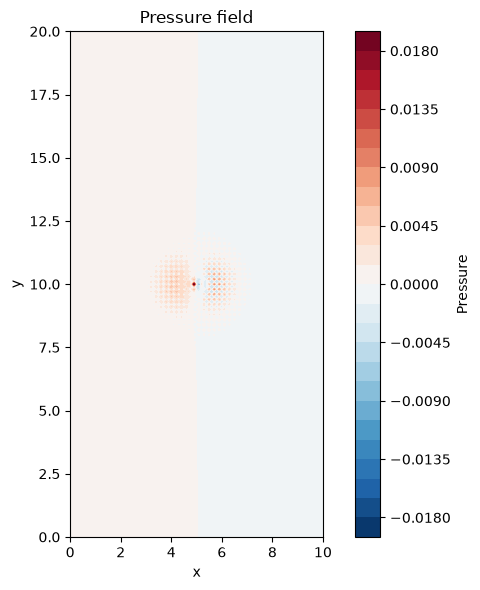

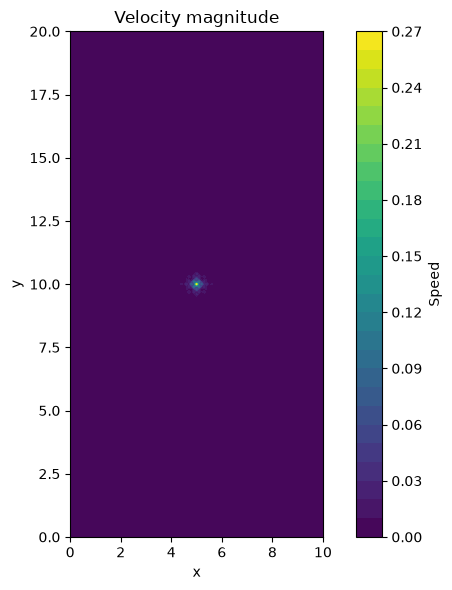

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Grid
Nx, Ny = 101, 201
dx, dy = 0.1, 0.1

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy
X, Y = np.meshgrid(x, y, indexing="ij")

# Fluid properties
rho = 1.0
nu = 0.01
dt = 0.001
t_end = 0.1

# Initialize fields
u = np.zeros((Nx, Ny))
v = np.zeros((Nx, Ny))
p = np.zeros((Nx, Ny))

# Localized velocity disturbance at the centre
i, j = Nx // 2, Ny // 2
u[i, j] = 1.0

# Run the solver
u, v, p = solve_NS(u, v, p, rho, nu, dt, t_end, dx, dy, logs=True)

# Plot pressure
fig, ax = plt.subplots(figsize=(7, 6))
contour = ax.contourf(X, Y, p, levels=30, cmap="RdBu_r")
fig.colorbar(contour, ax=ax, label="Pressure")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Pressure field")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# Plot velocity magnitude
speed = np.sqrt(u**2 + v**2)

fig, ax = plt.subplots(figsize=(7, 6))
contour = ax.contourf(X, Y, speed, levels=30, cmap="viridis")
fig.colorbar(contour, ax=ax, label="Speed")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Velocity magnitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()